In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

print("ML LIBRARIES LOADED")

ML LIBRARIES LOADED


In [13]:
X_train = pd.read_csv("../data/processed/X_train_processed.csv")
X_test = pd.read_csv("../data/processed/X_test_processed.csv")

y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (9600, 18)
Testing Features: (2400, 18)
Training Target: (9600,)
Testing Target: (2400,)


In [14]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("LOGISTIC REGRESSION TRAINED")

LOGISTIC REGRESSION TRAINED


In [15]:
y_pred_logistic = logistic_model.predict(X_test)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions Generated")
print("First 10 Predictions:", y_pred_logistic[:10])
print("First 10 Probabilities:", y_prob_logistic[:10])

Predictions Generated
First 10 Predictions: [0 0 0 1 0 1 1 0 0 0]
First 10 Probabilities: [0.09335653 0.00658841 0.00396903 0.9443663  0.10218144 0.917124
 0.97847961 0.07082009 0.00773299 0.02451495]


In [16]:
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

LOGISTIC REGRESSION RESULTS
Accuracy : 0.8567
Precision: 0.7915
Recall   : 0.7178
F1 Score : 0.7529
ROC-AUC  : 0.9203


In [17]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

print("DECISION TREE TRAINED")

DECISION TREE TRAINED


In [18]:
y_pred_tree = decision_tree_model.predict(X_test)
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

print("DECISION TREE PREDICTIONS GENERATED")

DECISION TREE PREDICTIONS GENERATED


In [19]:
accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(y_test, y_pred_tree)
recall_tree = recall_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree)
roc_auc_tree = roc_auc_score(y_test, y_prob_tree)

print("DECISION TREE RESULTS")
print("=" * 40)
print("Accuracy :", round(accuracy_tree, 4))
print("Precision:", round(precision_tree, 4))
print("Recall   :", round(recall_tree, 4))
print("F1 Score :", round(f1_tree, 4))
print("ROC-AUC  :", round(roc_auc_tree, 4))

DECISION TREE RESULTS
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [20]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

print("Decision Tree Confusion Matrix:")
print(cm_tree)

Decision Tree Confusion Matrix:
[[1670    0]
 [   0  730]]


In [21]:
print("Tree Depth:", decision_tree_model.get_depth())
print("Number of Leaves:", decision_tree_model.get_n_leaves())

Tree Depth: 3
Number of Leaves: 4


In [22]:
feature_importance_tree = pd.Series(
    decision_tree_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Decision Tree Feature Importance:")
print(feature_importance_tree)

Decision Tree Feature Importance:
aptitude_score          0.374070
cgpa                    0.336497
coding_skills           0.289432
gender_Male             0.000000
degree_BE               0.000000
degree_BSc              0.000000
branch_Electrical       0.000000
degree_BTech            0.000000
branch_CS               0.000000
branch_DS               0.000000
age                     0.000000
branch_Mechanical       0.000000
branch_IT               0.000000
backlogs                0.000000
certifications          0.000000
internships             0.000000
communication_skills    0.000000
projects                0.000000
dtype: float64


In [23]:
from sklearn.tree import export_text

tree_rules = export_text(
    decision_tree_model,
    feature_names=list(X_train.columns)
)

print(tree_rules)

|--- coding_skills <= -0.35
|   |--- class: 0
|--- coding_skills >  -0.35
|   |--- aptitude_score <= -0.57
|   |   |--- class: 0
|   |--- aptitude_score >  -0.57
|   |   |--- cgpa <= -0.92
|   |   |   |--- class: 0
|   |   |--- cgpa >  -0.92
|   |   |   |--- class: 1



In [24]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("RANDOM FOREST TRAINED")

RANDOM FOREST TRAINED


In [25]:
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST PREDICTIONS GENERATED")

RANDOM FOREST PREDICTIONS GENERATED


In [26]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("RANDOM FOREST RESULTS")
print("=" * 40)
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))

RANDOM FOREST RESULTS
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [27]:
from xgboost import XGBClassifier

print("XGBOOST IMPORTED")

XGBOOST IMPORTED


In [28]:
import pandas as pd
import numpy as np

X_train = pd.read_csv("../data/processed/X_train_processed.csv")
X_test = pd.read_csv("../data/processed/X_test_processed.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (9600, 18)
Testing Features: (2400, 18)
Training Target: (9600,)
Testing Target: (2400,)


In [29]:
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss",
    n_jobs=2
)

xgb_model.fit(X_train, y_train)

print("XGBOOST TRAINED")

XGBOOST TRAINED


In [30]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBOOST PREDICTIONS GENERATED")

XGBOOST PREDICTIONS GENERATED


In [31]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("METRICS IMPORTED")

METRICS IMPORTED


In [32]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("XGBOOST RESULTS")
print("=" * 40)
print("Accuracy :", round(accuracy_xgb, 4))
print("Precision:", round(precision_xgb, 4))
print("Recall   :", round(recall_xgb, 4))
print("F1 Score :", round(f1_xgb, 4))
print("ROC-AUC  :", round(roc_auc_xgb, 4))

XGBOOST RESULTS
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0


In [33]:
import pandas as pd

X_test = pd.read_csv("../data/processed/X_test_processed.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("TEST DATA LOADED")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

TEST DATA LOADED
X_test: (2400, 18)
y_test: (2400,)


In [34]:
print("Logistic:", "y_pred_logistic" in globals())
print("Decision Tree:", "y_pred_tree" in globals())
print("Random Forest:", "y_pred_rf" in globals())
print("XGBoost:", "y_pred_xgb" in globals())

Logistic: True
Decision Tree: True
Random Forest: True
XGBoost: True


In [35]:
X_train = pd.read_csv("../data/processed/X_train_processed.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()

print("TRAINING DATA LOADED")
print(X_train.shape)
print(y_train.shape)

TRAINING DATA LOADED
(9600, 18)
(9600,)


In [36]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("LOGISTIC PREDICTIONS READY")

LOGISTIC PREDICTIONS READY


In [37]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("LOGISTIC PREDICTIONS READY")

LOGISTIC PREDICTIONS READY


In [38]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

print("RANDOM FOREST PREDICTIONS READY")

RANDOM FOREST PREDICTIONS READY


In [39]:
print("Logistic:", "y_pred_logistic" in globals())
print("Decision Tree:", "y_pred_tree" in globals())
print("Random Forest:", "y_pred_rf" in globals())
print("XGBoost:", "y_pred_xgb" in globals())

Logistic: True
Decision Tree: True
Random Forest: True
XGBoost: True


In [40]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

print("DECISION TREE PREDICTIONS READY")

DECISION TREE PREDICTIONS READY


In [41]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

y_pred_tree = decision_tree_model.predict(X_test)

print("DECISION TREE PREDICTIONS READY")

DECISION TREE PREDICTIONS READY


In [42]:
print("Logistic:", "y_pred_logistic" in globals())
print("Decision Tree:", "y_pred_tree" in globals())
print("Random Forest:", "y_pred_rf" in globals())
print("XGBoost:", "y_pred_xgb" in globals())

Logistic: True
Decision Tree: True
Random Forest: True
XGBoost: True


In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("CONFUSION MATRIX TOOLS READY")

CONFUSION MATRIX TOOLS READY


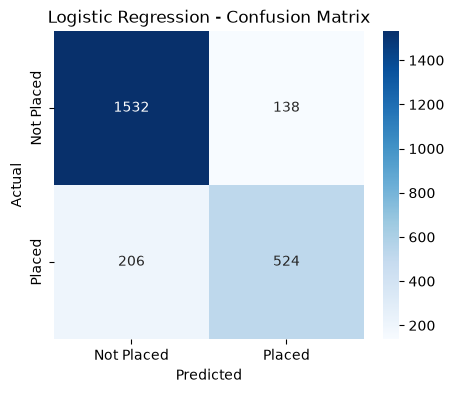

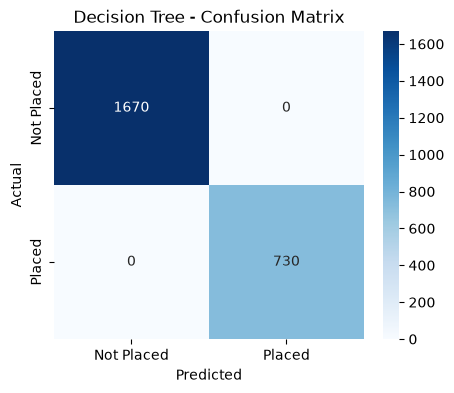

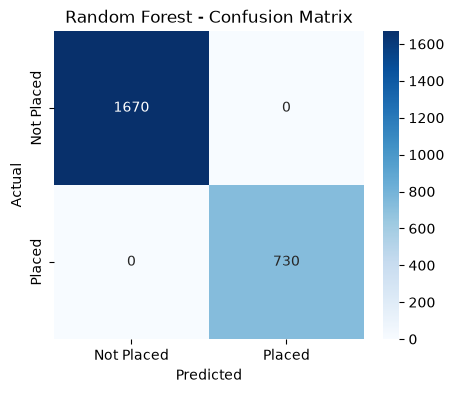

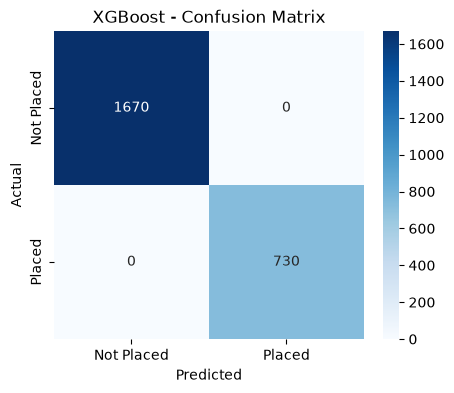

In [44]:
models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Placed", "Placed"],
        yticklabels=["Not Placed", "Placed"]
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

In [45]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("ALL MODEL PROBABILITIES READY")

ALL MODEL PROBABILITIES READY


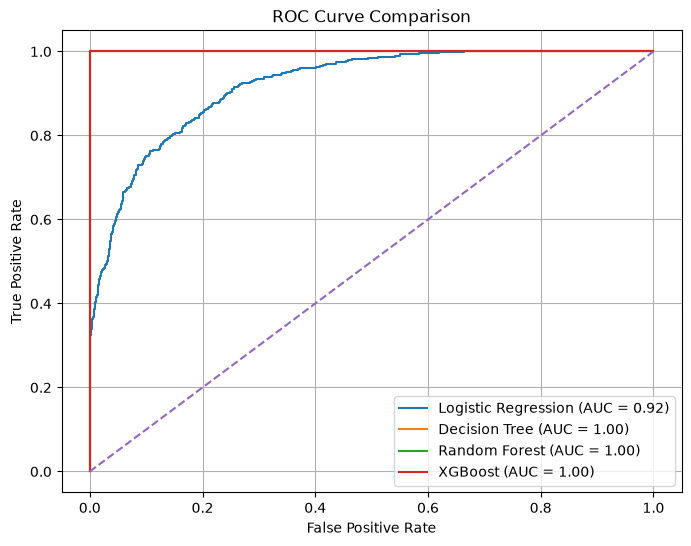

In [46]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_logistic)
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_prob_tree)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_logistic):.2f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {roc_auc_score(y_test, y_prob_tree):.2f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.2f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f"XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.2f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

In [47]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgb_model
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    print(name)
    print("CV Scores:", scores)
    print("Mean CV Accuracy:", scores.mean())
    print()

Logistic Regression
CV Scores: [0.85       0.8359375  0.85364583 0.83958333 0.8421875 ]
Mean CV Accuracy: 0.8442708333333332

Decision Tree
CV Scores: [1. 1. 1. 1. 1.]
Mean CV Accuracy: 1.0



Random Forest
CV Scores: [1. 1. 1. 1. 1.]
Mean CV Accuracy: 1.0

XGBoost
CV Scores: [1. 1. 1. 1. 1.]
Mean CV Accuracy: 1.0



In [48]:
import joblib
import os
import pandas as pd

best_model = logistic_model

os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/best_model.pkl")

model_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Test Accuracy": [0.8567, 1.0, 1.0, 1.0],
    "CV Accuracy": [
        0.8442708333333332,
        1.0,
        1.0,
        1.0
    ]
})

model_summary.to_csv("../models/model_comparison.csv", index=False)

print("BEST MODEL:", type(best_model).__name__)
print("MODEL SAVED: ../models/best_model.pkl")
print("COMPARISON SAVED: ../models/model_comparison.csv")

BEST MODEL: LogisticRegression
MODEL SAVED: ../models/best_model.pkl
COMPARISON SAVED: ../models/model_comparison.csv


In [49]:

import joblib
from pathlib import Path

model_path = Path("../models/best_model.pkl")
decision_tree_model = joblib.load(model_path)

print("Model loaded:", type(decision_tree_model).__name__)

Model loaded: LogisticRegression


In [ ]:

import joblib
from pathlib import Path

encoder = joblib.load("../models/encoder.pkl")
scaler = joblib.load("../models/scaler.pkl")

categorical_features = ["gender", "degree", "branch"]
numerical_features = [
    "age", "cgpa", "backlogs", "internships",
    "certifications", "coding_skills",
    "communication_skills", "aptitude_score", "projects"
]

encoded_names = encoder.get_feature_names_out(categorical_features)
processed_feature_names = list(encoded_names) + numerical_features

for i, name in enumerate(processed_feature_names):
    print(f"feature_{i}: {name}")

feature_0: gender_Male
feature_1: degree_BE
feature_2: degree_BSc
feature_3: degree_BTech
feature_4: branch_CS
feature_5: branch_DS
feature_6: branch_Electrical
feature_7: branch_IT
feature_8: branch_Mechanical
feature_9: age
feature_10: cgpa
feature_11: backlogs
feature_12: internships
feature_13: certifications
feature_14: coding_skills
feature_15: communication_skills
feature_16: aptitude_score
feature_17: projects


In [ ]:

import pandas as pd
import joblib
from sklearn.metrics import accuracy_score

df = pd.read_csv("../data/processed/student_placement_cleaned.csv")
scaler = joblib.load("../models/scaler.pkl")

numerical_features = [
    "age", "cgpa", "backlogs", "internships",
    "certifications", "coding_skills",
    "communication_skills", "aptitude_score", "projects"
]

scaled = scaler.transform(df[numerical_features])

coding = scaled[:, numerical_features.index("coding_skills")]
aptitude = scaled[:, numerical_features.index("aptitude_score")]
cgpa = scaled[:, numerical_features.index("cgpa")]

rule_predictions = (
    (coding > -0.35) &
    (aptitude > -0.57) &
    (cgpa > -0.92)
).astype(int)

actual = df["placed"].astype(int)

print("Dataset rows:", len(df))
print("Actual placement counts:")
print(actual.value_counts().sort_index())
print("\nAccuracy of the three-rule match:",
      f"{accuracy_score(actual, rule_predictions) * 100:.2f}%")
print("\nComparison (actual label vs rule prediction):")
print(pd.crosstab(actual, rule_predictions,
                  rownames=["Actual"], colnames=["Rule prediction"]))

Dataset rows: 12000
Actual placement counts:
placed
0    8348
1    3652
Name: count, dtype: int64

Accuracy of the three-rule match: 100.00%

Comparison (actual label vs rule prediction):
Rule prediction     0     1
Actual                     
0                8348     0
1                   0  3652


In [ ]:
df = pd.read_csv("../data/processed/student_placement_cleaned.csv")

features = ["coding_skills", "aptitude_score", "cgpa"]

profiles = df.groupby(features)["placed"].nunique()

print("Unique profiles:", len(profiles))
print("Conflicting profiles:", (profiles > 1).sum())

Unique profiles: 11719
Conflicting profiles: 0


In [ ]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Sri Durga\OneDrive\Documents\student-placement-ds\data\processed\student_placement_cleaned.csv")
print(df.groupby("placed")[["cgpa", "coding_skills", "aptitude_score"]].agg(["min", "max", "mean"]))


       cgpa                coding_skills               aptitude_score      \
        min  max      mean           min max      mean            min max   
placed                                                                      
0       5.5  9.8  7.427245             1  10  4.611164             40  99   
1       6.5  9.8  8.143771             5  10  7.516429             60  99   

                   
             mean  
placed             
0       64.854816  
1       79.552574  
1


In [ ]:
print(df.groupby(["cgpa", "coding_skills", "aptitude_score"])["placed"].nunique().max())

1


In [ ]:
print(df.groupby("placed")[["cgpa", "coding_skills", "aptitude_score"]].quantile([0.25, 0.5, 0.75]))

             cgpa  coding_skills  aptitude_score
placed                                          
0      0.25  6.24            2.0            50.0
       0.50  7.31            4.0            61.0
       0.75  8.55            7.0            80.0
1      0.25  7.30            6.0            70.0
       0.50  8.13            8.0            80.0
       0.75  8.99            9.0            90.0
